## Setup and data

In [1]:
import os, json, time, shutil, warnings, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix, classification_report
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid')

SEED = 42; keras.utils.set_random_seed(SEED)
print('TensorFlow', tf.__version__, '| GPUs:', tf.config.list_physical_devices('GPU'))

from google.colab import drive
drive.mount('/content/drive')
DRIVE_DIR = '/content/drive/MyDrive/SignSense_data'; WORK, OUT, MODELS = '/content/work', '/content/results', '/content/results/models'
for d in (WORK, OUT, MODELS): os.makedirs(d, exist_ok=True)
for f in ['dynamic_landmarks.npz', 'label_map.json']: shutil.copy(os.path.join(DRIVE_DIR, f), WORK)

lm = json.load(open(f'{WORK}/label_map.json')); STATIC, DYNAMIC = lm['static_classes'], lm['dynamic_classes']; C = len(DYNAMIC)
npz = np.load(f'{WORK}/dynamic_landmarks.npz', allow_pickle=False)
X, M, split, files = npz['X'], npz['mask'], npz['split'], npz['files']; y = (npz['y'] - len(STATIC)).astype('int32')
dev = np.isin(split, ['train', 'val']); te = split == 'test'
X_dev, M_dev, y_dev, f_dev = X[dev], M[dev], y[dev], files[dev]; X_te, M_te, y_te, f_te = X[te], M[te], y[te], files[te]
print('All:', X.shape, '| dev (train+val):', X_dev.shape, '| test:', X_te.shape, '| classes:', DYNAMIC)
print('Dev class counts:', dict(zip(DYNAMIC, np.bincount(y_dev))), '| test class counts:', dict(zip(DYNAMIC, np.bincount(y_te))))

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive
All: (393, 88, 63) | dev (train+val): (334, 88, 63) | test: (59, 88, 63) | classes: ['2-Hay', 'Alifmad', 'Aray', 'Jeem']
Dev class counts: {'2-Hay': np.int64(74), 'Alifmad': np.int64(89), 'Aray': np.int64(87), 'Jeem': np.int64(84)} | test class counts: {'2-Hay': np.int64(13), 'Alifmad': np.int64(16), 'Aray': np.int64(15), 'Jeem': np.int64(15)}


## 1. Features, augmentation, models
- **Features:** 63 normalized landmark values + 1 detection flag per frame. Optional **velocity** (frame-to-frame change, 63 more values) captures the motion explicitly.
- **Augmentation (training only):** small in-plane rotation (±10°), rescaling (±10%), Gaussian jitter and a small time shift, applied to the landmarks of detected frames. Four augmented copies per training video.
- **Early stopping** uses a 15% part of each training set (inner validation), so the held-out fold is never used to stop training.

In [2]:
def make_feats(X, M, vel):
    F = np.concatenate([X, M[..., None].astype('float32')], axis=-1)
    if vel:
        V = np.zeros_like(X); V[:, 1:] = (X[:, 1:] - X[:, :-1]) * (M[:, 1:] & M[:, :-1])[..., None]
        F = np.concatenate([F, V], axis=-1)
    return F.astype('float32')

def aug_copies(X, M, y, rng, copies=4):
    Xs, Ms, ys = [X], [M], [y]
    for _ in range(copies):
        Xa, Ma = np.empty_like(X), np.empty_like(M)
        for i in range(len(X)):
            x, m = X[i].copy(), M[i]
            th = np.deg2rad(rng.uniform(-10, 10)); R = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]], 'float32')
            p = x.reshape(-1, 21, 3); p[..., :2] = p[..., :2] @ R.T; x = p.reshape(-1, 63)   # rotate x,y of every landmark
            x[m] = x[m] * rng.uniform(.9, 1.1) + rng.normal(0, .02, x[m].shape)
            sh = int(rng.integers(-4, 5)); Xa[i], Ma[i] = np.roll(x, sh, 0), np.roll(m, sh, 0)
            Xa[i][~Ma[i]] = 0
        Xs.append(Xa); Ms.append(Ma); ys.append(y)
    return np.concatenate(Xs), np.concatenate(Ms), np.concatenate(ys)

def summary_feats(F): return np.concatenate([F.mean(1), F.std(1), F.min(1), F.max(1)], axis=1)

def build_nn(family, Ftr, p):
    norm = layers.Normalization(axis=-1); norm.adapt(Ftr)
    inp = keras.Input(Ftr.shape[1:]); x = norm(inp)
    if family == 'LSTM':   x = layers.LSTM(p['units'])(x); x = layers.Dropout(p['dropout'])(x)
    elif family == 'GRU':  x = layers.GRU(p['units'])(x); x = layers.Dropout(p['dropout'])(x)
    elif family == 'CNN1D':
        for _ in range(2): x = layers.Conv1D(p['filters'], 5, padding='same', activation='relu')(x); x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x)
        x = layers.GlobalAveragePooling1D()(x); x = layers.Dropout(p['dropout'])(x)
    elif family == 'MLP':
        x = layers.Flatten()(x); x = layers.Dense(p['hidden'], activation='relu')(x); x = layers.Dropout(p['dropout'])(x)
        x = layers.Dense(p['hidden'] // 2, activation='relu')(x); x = layers.Dropout(p['dropout'])(x)
    out = layers.Dense(C, activation='softmax')(x)
    m = keras.Model(inp, out, name=family); m.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

def fit_predict(family, p, Xtr, Mtr, ytr, Xev, Mev, vel, aug, seed, return_model=False):
    rng = np.random.default_rng(seed)
    if family == 'RF':
        Ftr = make_feats(Xtr, Mtr, True); clf = RandomForestClassifier(400, random_state=seed, n_jobs=-1).fit(summary_feats(Ftr), ytr)
        return clf.predict_proba(summary_feats(make_feats(Xev, Mev, True))), None
    keras.utils.set_random_seed(seed)
    i_tr, i_in = train_test_split(np.arange(len(Xtr)), test_size=0.15, stratify=ytr, random_state=seed)
    Xa, Ma, ya = (aug_copies(Xtr[i_tr], Mtr[i_tr], ytr[i_tr], rng) if aug else (Xtr[i_tr], Mtr[i_tr], ytr[i_tr]))
    Ft, Fi, Fe = make_feats(Xa, Ma, vel), make_feats(Xtr[i_in], Mtr[i_in], vel), make_feats(Xev, Mev, vel)
    model = build_nn(family, Ft, p)
    model.fit(Ft, ya, validation_data=(Fi, ytr[i_in]), epochs=60, batch_size=32, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)])
    probs = model.predict(Fe, verbose=0)
    if return_model: return probs, model
    keras.backend.clear_session(); return probs, None

def scores(yt, P):
    p = P.argmax(1); return accuracy_score(yt, p), f1_score(yt, p, average='macro')

FOLDS = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X_dev, y_dev))   # Same folds for every experiment
def cv_run(family, p, vel, aug):
    t0 = time.time(); accs, f1s = [], []
    for k, (a, b) in enumerate(FOLDS):
        P, _ = fit_predict(family, p, X_dev[a], M_dev[a], y_dev[a], X_dev[b], M_dev[b], vel, aug, seed=k)
        acc, f1 = scores(y_dev[b], P); accs.append(acc); f1s.append(f1)
    return {'cv_acc': np.mean(accs), 'cv_acc_std': np.std(accs), 'cv_f1': np.mean(f1s), 'cv_f1_std': np.std(f1s), 'fold_f1': f1s, 'secs': round(time.time() - t0)}

## 2. Ablation: do velocity features and augmentation help? (LSTM-64, 5-fold CV)

False False 0.9662 +- 0.0301
False True 0.9695 +- 0.0293
True False 0.9574 +- 0.0315
True True 0.9786 +- 0.0278

Chosen setting for all neural models -> velocity: True | augmentation: True


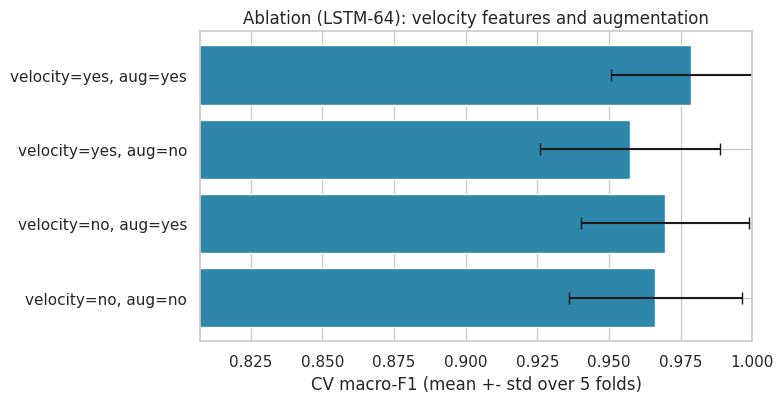

,velocity,augmentation,cv_acc,cv_acc_std,cv_f1,cv_f1_std,secs
0,False,False,0.9671,0.0304,0.9662,0.0301,60
1,False,True,0.9701,0.0298,0.9695,0.0293,71
2,True,False,0.9581,0.0318,0.9574,0.0315,48
3,True,True,0.9791,0.0277,0.9786,0.0278,63


In [3]:
AB = []
for vel, aug in itertools.product([False, True], [False, True]):
    r = cv_run('LSTM', {'units': 64, 'dropout': 0.3}, vel, aug); AB.append({'velocity': vel, 'augmentation': aug, **r}); print(AB[-1]['velocity'], AB[-1]['augmentation'], round(r['cv_f1'], 4), '+-', round(r['cv_f1_std'], 4))
ab = pd.DataFrame(AB); ab['setting'] = ab.apply(lambda r: f"velocity={'yes' if r.velocity else 'no'}, aug={'yes' if r.augmentation else 'no'}", axis=1)
best_row = ab.sort_values('cv_f1', ascending=False).iloc[0]; VEL, AUG = bool(best_row['velocity']), bool(best_row['augmentation'])
print('\nChosen setting for all neural models -> velocity:', VEL, '| augmentation:', AUG)
fig, ax = plt.subplots(figsize=(8, 4.2)); ax.barh(ab['setting'], ab['cv_f1'], xerr=ab['cv_f1_std'], color='#2E86AB', capsize=4)
ax.set_xlim(max(0, ab['cv_f1'].min() - .15), 1.0); ax.set_xlabel('CV macro-F1 (mean +- std over 5 folds)'); ax.set_title('Ablation (LSTM-64): velocity features and augmentation')
plt.tight_layout(); plt.savefig(f'{OUT}/p2_12_dynamic_ablation.png', dpi=130, bbox_inches='tight'); plt.show(); ab.drop(columns=['fold_f1', 'setting']).round(4)

**What it tells us:** the bars show whether explicit motion (velocity) and augmentation improve generalisation across folds. The setting with the best mean is used for every neural model below; if bars overlap within their error bars, the effect is small.

## 3. Hyperparameter tuning (5-fold CV) and model-family comparison

In [4]:
GRID = {'RF': [{}],
        'MLP': [{'hidden': h, 'dropout': 0.3} for h in (128, 256)],
        'CNN1D': [{'filters': f, 'dropout': 0.3} for f in (32, 64)],
        'LSTM': [{'units': u, 'dropout': d} for u in (32, 64, 128) for d in (0.3, 0.5)],
        'GRU':  [{'units': u, 'dropout': d} for u in (32, 64, 128) for d in (0.3, 0.5)]}
TUNE = []
for fam, plist in GRID.items():
    for p in plist:
        r = cv_run(fam, p, VEL, AUG); TUNE.append({'family': fam, 'params': json.dumps(p), **r})
        print(f"{fam:6s} {json.dumps(p):38s} CV F1 {r['cv_f1']:.4f} +- {r['cv_f1_std']:.4f}  ({r['secs']}s)")
tune = pd.DataFrame(TUNE); tune.drop(columns=['fold_f1']).round(4)

RF     {}                                     CV F1 0.9877 +- 0.0062  (8s)
MLP    {"hidden": 128, "dropout": 0.3}        CV F1 0.9625 +- 0.0295  (59s)
MLP    {"hidden": 256, "dropout": 0.3}        CV F1 0.9631 +- 0.0391  (52s)
CNN1D  {"filters": 32, "dropout": 0.3}        CV F1 0.9811 +- 0.0231  (112s)
CNN1D  {"filters": 64, "dropout": 0.3}        CV F1 0.9784 +- 0.0267  (103s)
LSTM   {"units": 32, "dropout": 0.3}          CV F1 0.9850 +- 0.0301  (90s)
LSTM   {"units": 32, "dropout": 0.5}          CV F1 0.9790 +- 0.0346  (95s)
LSTM   {"units": 64, "dropout": 0.3}          CV F1 0.9754 +- 0.0280  (60s)
LSTM   {"units": 64, "dropout": 0.5}          CV F1 0.9749 +- 0.0317  (62s)
LSTM   {"units": 128, "dropout": 0.3}         CV F1 0.9725 +- 0.0331  (68s)
LSTM   {"units": 128, "dropout": 0.5}         CV F1 0.9727 +- 0.0258  (65s)
GRU    {"units": 32, "dropout": 0.3}          CV F1 0.9673 +- 0.0307  (86s)
GRU    {"units": 32, "dropout": 0.5}          CV F1 0.9669 +- 0.0260  (83s)
GRU    {"un

,family,params,cv_acc,cv_acc_std,cv_f1,cv_f1_std,secs
0,RF,{},0.9880,0.0060,0.9877,0.0062,8
1,MLP,"{""hidden"": 128, ""dropout"": 0.3}",0.9640,0.0278,0.9625,0.0295,59
2,MLP,"{""hidden"": 256, ""dropout"": 0.3}",0.9640,0.0385,0.9631,0.0391,52
3,CNN1D,"{""filters"": 32, ""dropout"": 0.3}",0.9820,0.0221,0.9811,0.0231,112
4,CNN1D,"{""filters"": 64, ""dropout"": 0.3}",0.9790,0.0261,0.9784,0.0267,103
5,LSTM,"{""units"": 32, ""dropout"": 0.3}",0.9851,0.0299,0.9850,0.0301,90
6,LSTM,"{""units"": 32, ""dropout"": 0.5}",0.9791,0.0348,0.9790,0.0346,95
7,LSTM,"{""units"": 64, ""dropout"": 0.3}",0.9760,0.0277,0.9754,0.0280,60
8,LSTM,"{""units"": 64, ""dropout"": 0.5}",0.9760,0.0308,0.9749,0.0317,62
9,LSTM,"{""units"": 128, ""dropout"": 0.3}",0.9730,0.0332,0.9725,0.0331,68


PRIMARY family (best CV macro-F1): RF {}


,family,params,cv_acc,cv_acc_std,cv_f1,cv_f1_std,secs
0,RF,{},0.9880,0.0060,0.9877,0.0062,8
1,LSTM,"{""units"": 32, ""dropout"": 0.3}",0.9851,0.0299,0.9850,0.0301,90
2,CNN1D,"{""filters"": 32, ""dropout"": 0.3}",0.9820,0.0221,0.9811,0.0231,112
3,GRU,"{""units"": 32, ""dropout"": 0.3}",0.9671,0.0304,0.9673,0.0307,86
4,MLP,"{""hidden"": 256, ""dropout"": 0.3}",0.9640,0.0385,0.9631,0.0391,52


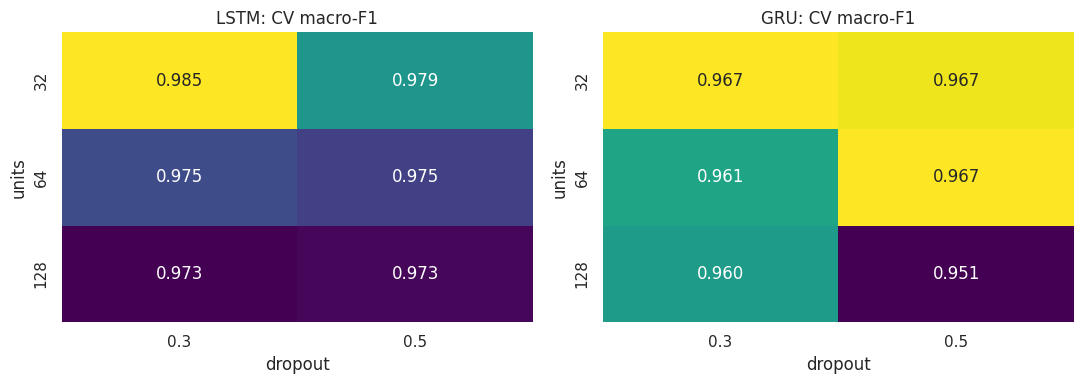

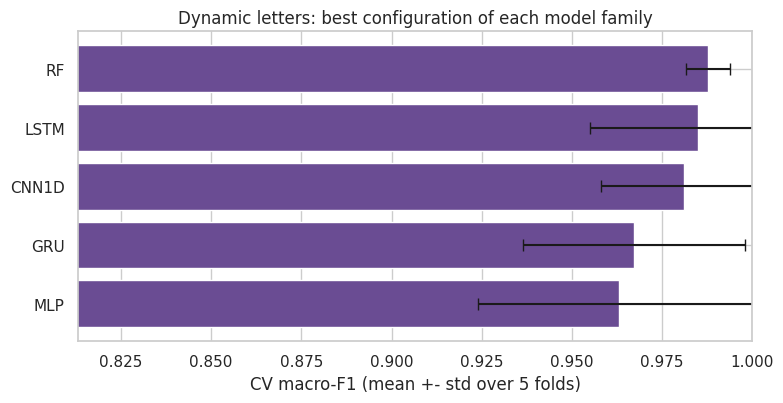

In [5]:
best = tune.sort_values('cv_f1', ascending=False).groupby('family').head(1).sort_values('cv_f1', ascending=False).reset_index(drop=True)
PRIMARY = best.iloc[0]['family']; print('PRIMARY family (best CV macro-F1):', PRIMARY, json.loads(best.iloc[0]['params']))
display(best.drop(columns=['fold_f1']).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, fam in zip(axes, ['LSTM', 'GRU']):
    t = tune[tune.family == fam].copy(); t['units'] = t['params'].map(lambda s: json.loads(s)['units']); t['dropout'] = t['params'].map(lambda s: json.loads(s)['dropout'])
    sns.heatmap(t.pivot(index='units', columns='dropout', values='cv_f1'), annot=True, fmt='.3f', cmap='viridis', ax=ax, cbar=False); ax.set_title(f'{fam}: CV macro-F1')
plt.tight_layout(); plt.savefig(f'{OUT}/p2_13_dynamic_tuning.png', dpi=130, bbox_inches='tight'); plt.show()

fig, ax = plt.subplots(figsize=(8, 4.2)); b = best.iloc[::-1]
ax.barh(b['family'], b['cv_f1'], xerr=b['cv_f1_std'], color='#6A4C93', capsize=4); ax.set_xlim(max(0, b['cv_f1'].min() - .15), 1.0)
ax.set_xlabel('CV macro-F1 (mean +- std over 5 folds)'); ax.set_title('Dynamic letters: best configuration of each model family')
plt.tight_layout(); plt.savefig(f'{OUT}/p2_14_dynamic_cv_comparison.png', dpi=130, bbox_inches='tight'); plt.show()

**What it tells us:** the heatmaps show how sensitive the recurrent models are to size and dropout (flat = robust). The bar chart compares the best version of each family using the same folds. Differences smaller than the error bars are not reliable with only 334 videos.

## 4. Final test-set evaluation
Each family's best configuration is trained on all 334 dev videos (3 seeds for the neural models) and evaluated **once** on the 59 test videos. The selection of the primary family was made above from cross-validation only. Reported: mean ± std accuracy over seeds (what a single trained model gets), and the metrics of the **seed-averaged** probabilities.

In [6]:
SEEDS = [0, 1, 2]; PT, SEEDACC, SAVED = {}, {}, {}
for _, r in best.iterrows():
    fam, p = r['family'], json.loads(r['params']); probs = []
    for s in (SEEDS if fam != 'RF' else [0]):
        P, mdl = fit_predict(fam, p, X_dev, M_dev, y_dev, X_te, M_te, VEL, AUG, seed=s, return_model=(fam != 'RF'))
        probs.append(P)
        if mdl is not None: mdl.save(f'{MODELS}/dynamic_{fam.lower()}_seed{s}.keras'); SAVED[(fam, s)] = mdl
    PT[fam] = np.mean(probs, axis=0); SEEDACC[fam] = [accuracy_score(y_te, P.argmax(1)) for P in probs]
    print(fam, 'per-seed test accuracy:', np.round(SEEDACC[fam], 4))

RF per-seed test accuracy: [1.]
LSTM per-seed test accuracy: [0.9831 0.9661 0.9492]
CNN1D per-seed test accuracy: [1. 1. 1.]
GRU per-seed test accuracy: [0.9661 0.9831 0.9831]
MLP per-seed test accuracy: [1. 1. 1.]


,model,accuracy,precision,recall,f1_macro,seed_acc_mean,seed_acc_std,acc_ci_low,acc_ci_high
0,RF,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,1.0
1,CNN1D,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,1.0
2,MLP,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,1.0
3,LSTM,0.9831,0.9853,0.9833,0.9838,0.9661,0.0138,0.9492,1.0
4,GRU,0.9661,0.9665,0.9688,0.9660,0.9774,0.0080,0.9153,1.0


,comparison,mean_diff,ci_low,ci_high,clearly_different
0,RF - LSTM,0.0163,0.0,0.0508,False
1,RF - CNN1D,0.0000,0.0,0.0000,False
2,RF - GRU,0.0345,0.0,0.0847,False
3,RF - MLP,0.0000,0.0,0.0000,False


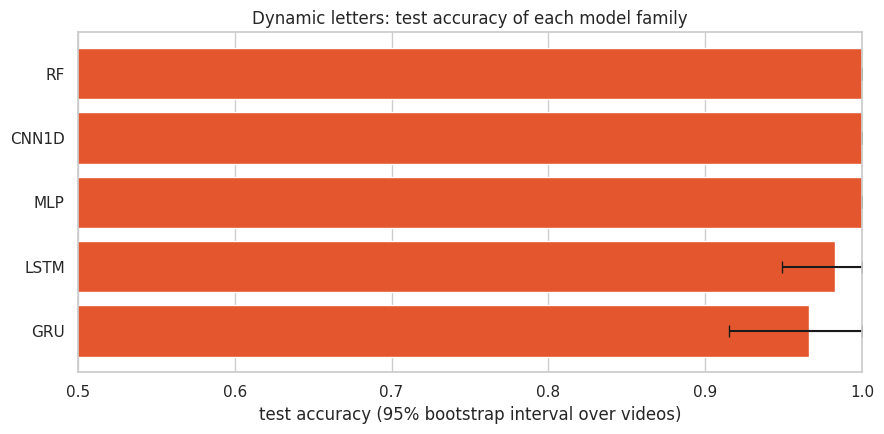

In [7]:
rows = []
for fam, P in PT.items():
    p = P.argmax(1); pr, rc, f1, _ = precision_recall_fscore_support(y_te, p, average='macro', zero_division=0)
    rows.append({'model': fam, 'accuracy': accuracy_score(y_te, p), 'precision': pr, 'recall': rc, 'f1_macro': f1,
                 'seed_acc_mean': np.mean(SEEDACC[fam]), 'seed_acc_std': np.std(SEEDACC[fam])})
T = pd.DataFrame(rows).sort_values('f1_macro', ascending=False).reset_index(drop=True)

rng = np.random.default_rng(0); B = 5000; idx = rng.integers(0, len(y_te), (B, len(y_te)))
boot = {f: (PT[f].argmax(1) == y_te)[idx].mean(1) for f in PT}
T['acc_ci_low'] = [np.percentile(boot[m], 2.5) for m in T['model']]; T['acc_ci_high'] = [np.percentile(boot[m], 97.5) for m in T['model']]
display(T.round(4))
dd = []
for f in PT:
    if f != PRIMARY:
        d = boot[PRIMARY] - boot[f]; dd.append({'comparison': f'{PRIMARY} - {f}', 'mean_diff': d.mean(), 'ci_low': np.percentile(d, 2.5), 'ci_high': np.percentile(d, 97.5)})
DD = pd.DataFrame(dd); DD['clearly_different'] = (DD['ci_low'] > 0) | (DD['ci_high'] < 0); display(DD.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5)); t = T.iloc[::-1]
ax.barh(t['model'], t['accuracy'], xerr=[t['accuracy'] - t['acc_ci_low'], t['acc_ci_high'] - t['accuracy']], color='#E4572E', capsize=4)
ax.set_xlim(.5, 1.0); ax.set_xlabel('test accuracy (95% bootstrap interval over videos)'); ax.set_title('Dynamic letters: test accuracy of each model family')
plt.tight_layout(); plt.savefig(f'{OUT}/p2_15_dynamic_test_comparison.png', dpi=130, bbox_inches='tight'); plt.show()

**What it tells us:** the intervals are wide because there are only 59 test videos. When two intervals overlap strongly, the models cannot be separated with this test set, and cross-validation (which used 334 videos) is the better guide.

## 5. Error analysis (primary model)

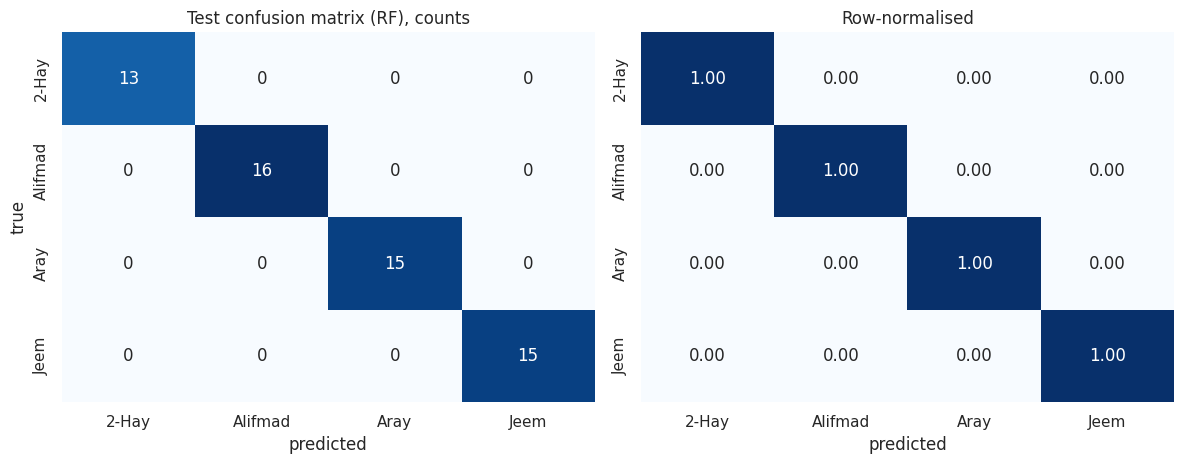

              precision    recall  f1-score   support

       2-Hay      1.000     1.000     1.000        13
     Alifmad      1.000     1.000     1.000        16
        Aray      1.000     1.000     1.000        15
        Jeem      1.000     1.000     1.000        15

    accuracy                          1.000        59
   macro avg      1.000     1.000     1.000        59
weighted avg      1.000     1.000     1.000        59



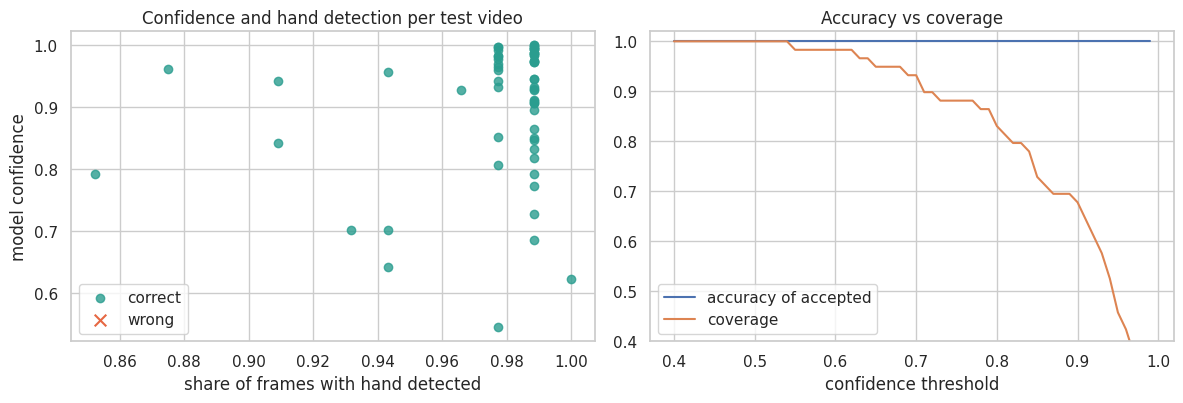

Mean hand-detection rate: correct 0.976 | wrong nan


,file,true,predicted,confidence,detected_frames


In [8]:
P = PT[PRIMARY]; pred = P.argmax(1); cm = confusion_matrix(y_te, pred, labels=range(C))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=DYNAMIC, yticklabels=DYNAMIC, ax=axes[0], cbar=False); axes[0].set_title(f'Test confusion matrix ({PRIMARY}), counts'); axes[0].set_xlabel('predicted'); axes[0].set_ylabel('true')
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, xticklabels=DYNAMIC, yticklabels=DYNAMIC, ax=axes[1], cbar=False); axes[1].set_title('Row-normalised'); axes[1].set_xlabel('predicted')
plt.tight_layout(); plt.savefig(f'{OUT}/p2_16_dynamic_confusion.png', dpi=130, bbox_inches='tight'); plt.show()
print(classification_report(y_te, pred, target_names=DYNAMIC, digits=3))

det = M_te.mean(1); ok = pred == y_te
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].scatter(det[ok], P.max(1)[ok], c='#2A9D8F', label='correct', alpha=.8); axes[0].scatter(det[~ok], P.max(1)[~ok], c='#E4572E', label='wrong', alpha=.9, marker='x', s=70)
axes[0].set_xlabel('share of frames with hand detected'); axes[0].set_ylabel('model confidence'); axes[0].set_title('Confidence and hand detection per test video'); axes[0].legend()
conf = P.max(1); ts = np.linspace(.4, .99, 60); axes[1].plot(ts, [ok[conf >= t].mean() if (conf >= t).any() else np.nan for t in ts], label='accuracy of accepted'); axes[1].plot(ts, [(conf >= t).mean() for t in ts], label='coverage')
axes[1].set_xlabel('confidence threshold'); axes[1].set_title('Accuracy vs coverage'); axes[1].legend(); axes[1].set_ylim(.4, 1.02)
plt.tight_layout(); plt.savefig(f'{OUT}/p2_17_dynamic_error_analysis.png', dpi=130, bbox_inches='tight'); plt.show()
wrong = pd.DataFrame({'file': f_te[~ok], 'true': np.array(DYNAMIC)[y_te[~ok]], 'predicted': np.array(DYNAMIC)[pred[~ok]], 'confidence': conf[~ok].round(3), 'detected_frames': det[~ok].round(2)})
print('Mean hand-detection rate: correct', round(det[ok].mean(), 3), '| wrong', round(det[~ok].mean(), 3)); wrong

**What it tells us:** the confusion matrix shows which motions are mixed up. If wrong videos have a lower share of detected frames, errors come from MediaPipe losing the hand rather than from the sequence model. The right panel shows how a confidence threshold trades accepted predictions against accuracy, which the live pipeline will use.

## 6. Inference time and saving

In [9]:
def cpu_latency(model, n=100):
    x = tf.constant(make_feats(X_te[:1], M_te[:1], VEL)); fn = tf.function(lambda a: model(a, training=False))
    with tf.device('/CPU:0'):
        for _ in range(10): fn(x).numpy()
        t = time.time()
        for _ in range(n): fn(x).numpy()
    return (time.time() - t) / n * 1000
LAT = [{'model': fam, 'params': SAVED[(fam, 0)].count_params(), 'cpu_latency_ms_per_video': round(cpu_latency(SAVED[(fam, 0)]), 2)} for fam in PT if fam != 'RF']
lat = pd.DataFrame(LAT); display(lat)

tune.drop(columns=['fold_f1']).to_csv(f'{OUT}/dynamic_cv_tuning.csv', index=False); best.drop(columns=['fold_f1']).to_csv(f'{OUT}/dynamic_cv_best.csv', index=False)
ab.drop(columns=['fold_f1', 'setting']).to_csv(f'{OUT}/dynamic_ablation.csv', index=False); T.to_csv(f'{OUT}/dynamic_results_test.csv', index=False)
DD.to_csv(f'{OUT}/dynamic_bootstrap_diffs.csv', index=False); lat.to_csv(f'{OUT}/dynamic_latency.csv', index=False)
json.dump({'velocity': VEL, 'augmentation': AUG, 'primary': PRIMARY, 'best': {r['family']: json.loads(r['params']) for _, r in best.iterrows()}}, open(f'{OUT}/dynamic_config.json', 'w'), indent=1)
np.savez_compressed(f'{OUT}/dynamic_test_predictions.npz', **{k: v.astype('float32') for k, v in PT.items()}, y=y_te, files=f_te)
os.makedirs(f'{DRIVE_DIR}/models', exist_ok=True); os.makedirs(f'{DRIVE_DIR}/results', exist_ok=True)
for f in os.listdir(MODELS): shutil.copy(f'{MODELS}/{f}', f'{DRIVE_DIR}/models/{f}')
for f in os.listdir(OUT):
    if os.path.isfile(f'{OUT}/{f}'): shutil.copy(f'{OUT}/{f}', f'{DRIVE_DIR}/results/{f}')
print(sorted(os.listdir(OUT)), sorted(os.listdir(MODELS)))

,model,params,cpu_latency_ms_per_video
0,LSTM,20867,4.40
1,CNN1D,26147,2.30
2,GRU,15843,4.06
3,MLP,2894979,3.74


['dynamic_ablation.csv', 'dynamic_bootstrap_diffs.csv', 'dynamic_config.json', 'dynamic_cv_best.csv', 'dynamic_cv_tuning.csv', 'dynamic_latency.csv', 'dynamic_results_test.csv', 'dynamic_test_predictions.npz', 'models', 'p2_12_dynamic_ablation.png', 'p2_13_dynamic_tuning.png', 'p2_14_dynamic_cv_comparison.png', 'p2_15_dynamic_test_comparison.png', 'p2_16_dynamic_confusion.png', 'p2_17_dynamic_error_analysis.png'] ['dynamic_cnn1d_seed0.keras', 'dynamic_cnn1d_seed1.keras', 'dynamic_cnn1d_seed2.keras', 'dynamic_gru_seed0.keras', 'dynamic_gru_seed1.keras', 'dynamic_gru_seed2.keras', 'dynamic_lstm_seed0.keras', 'dynamic_lstm_seed1.keras', 'dynamic_lstm_seed2.keras', 'dynamic_mlp_seed0.keras', 'dynamic_mlp_seed1.keras', 'dynamic_mlp_seed2.keras']


In [10]:
def hdr(t): print('\n' + '=' * 70 + f'\n{t}\n' + '=' * 70)
hdr('Ablation (LSTM-64, CV)'); print(ab.drop(columns=['fold_f1', 'setting']).round(4).to_string(index=False)); print('Chosen: velocity', VEL, '| augmentation', AUG)
hdr('Tuning (CV)'); print(tune.drop(columns=['fold_f1']).round(4).to_string(index=False))
hdr('Best per family (CV)'); print(best.drop(columns=['fold_f1']).round(4).to_string(index=False)); print('PRIMARY:', PRIMARY)
hdr('TEST results'); print(T.round(4).to_string(index=False))
hdr('Paired differences vs primary'); print(DD.round(4).to_string(index=False))
hdr('Confusion matrix (primary)'); print(pd.DataFrame(cm, index=DYNAMIC, columns=DYNAMIC).to_string())
print(classification_report(y_te, pred, target_names=DYNAMIC, digits=3))
hdr('Errors'); print('Detection rate correct / wrong:', round(det[ok].mean(), 3), round(det[~ok].mean(), 3)); print(wrong.to_string(index=False))
hdr('Latency (CPU)'); print(lat.to_string(index=False))
hdr('Files'); print(sorted(os.listdir(OUT)), sorted(os.listdir(MODELS)))


Ablation (LSTM-64, CV)
 velocity  augmentation  cv_acc  cv_acc_std  cv_f1  cv_f1_std  secs
    False         False  0.9671      0.0304 0.9662     0.0301    60
    False          True  0.9701      0.0298 0.9695     0.0293    71
     True         False  0.9581      0.0318 0.9574     0.0315    48
     True          True  0.9791      0.0277 0.9786     0.0278    63
Chosen: velocity True | augmentation True

Tuning (CV)
family                          params  cv_acc  cv_acc_std  cv_f1  cv_f1_std  secs
    RF                              {}  0.9880      0.0060 0.9877     0.0062     8
   MLP {"hidden": 128, "dropout": 0.3}  0.9640      0.0278 0.9625     0.0295    59
   MLP {"hidden": 256, "dropout": 0.3}  0.9640      0.0385 0.9631     0.0391    52
 CNN1D {"filters": 32, "dropout": 0.3}  0.9820      0.0221 0.9811     0.0231   112
 CNN1D {"filters": 64, "dropout": 0.3}  0.9790      0.0261 0.9784     0.0267   103
  LSTM   {"units": 32, "dropout": 0.3}  0.9851      0.0299 0.9850     0.0301    90
